In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/drive/MyDrive/ngelatihsiyolo

In [3]:
!unzip freepass-data-science-open-recruitment-bcc-2026.zip

Streaming output truncated to the last 5000 lines.
  inflating: test/images/2015_06540.jpg  
  inflating: test/images/2015_06541.jpg  
  inflating: test/images/2015_06542.jpg  
  inflating: test/images/2015_06545.jpg  
  inflating: test/images/2015_06547.jpg  
  inflating: test/images/2015_06548.jpg  
  inflating: test/images/2015_06549.jpg  
  inflating: test/images/2015_06550.jpg  
  inflating: test/images/2015_06554.jpg  
  inflating: test/images/2015_06555.jpg  
  inflating: test/images/2015_06557.jpg  
  inflating: test/images/2015_06558.jpg  
  inflating: test/images/2015_06559.jpg  
  inflating: test/images/2015_06560.jpg  
  inflating: test/images/2015_06561.jpg  
  inflating: test/images/2015_06565.jpg  
  inflating: test/images/2015_06566.jpg  
  inflating: test/images/2015_06567.jpg  
  inflating: test/images/2015_06570.jpg  
  inflating: test/images/2015_06572.jpg  
  inflating: test/images/2015_06573.jpg  
  inflating: test/images/2015_06574.jpg  
  inflating: test/images/

In [4]:
!ls

drive						     sample_submission.csv
freepass-data-science-open-recruitment-bcc-2026.zip  test
sample_data					     train


In [5]:
!ls train/images | head

2015_00001.png
2015_00004.jpg
2015_00006.jpg
2015_00010.jpg
2015_00013.jpg
2015_00018.jpg
2015_00020.jpg
2015_00021.jpg
2015_00022.jpg
2015_00023.jpg


In [6]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 50.9 MB/s eta 0:00:00


In [7]:
!yolo version

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
8.4.11


In [8]:
!mkdir -p dataset/images/train
!mkdir -p dataset/labels/train

In [9]:
!cp train/images/* dataset/images/train/

In [10]:
import os
from PIL import Image

class_map = {
    "Bicycle": 0, "Boat": 1, "Bottle": 2, "Bus": 3,
    "Car": 4, "Cat": 5, "Chair": 6, "Cup": 7,
    "Dog": 8, "Motorbike": 9, "People": 10, "Table": 11
}

ann_dir = "train/annotations"
img_dir = "dataset/images/train"
label_dir = "dataset/labels/train"

os.makedirs(label_dir, exist_ok=True)

converted = 0

for file in os.listdir(ann_dir):
    if not file.endswith(".txt"):
        continue

    img_name = file.replace(".txt", "")
    img_path = os.path.join(img_dir, img_name)

    if not os.path.exists(img_path):
        continue

    img = Image.open(img_path)
    W, H = img.size

    yolo_lines = []

    with open(os.path.join(ann_dir, file)) as f:
        for line in f:
            if line.startswith("%"):
                continue

            cls, x, y, w, h, *_ = line.strip().split()
            if cls not in class_map:
                continue

            x = float(x)
            y = float(y)
            w = float(w)
            h = float(h)

            xc = (x + w / 2) / W
            yc = (y + h / 2) / H
            wn = w / W
            hn = h / H

            if 0 < xc < 1 and 0 < yc < 1:
                yolo_lines.append(
                    f"{class_map[cls]} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}"
                )

    if yolo_lines:
        with open(os.path.join(label_dir, file.replace(".jpg.txt", ".txt").replace(".png.txt", ".txt")), "w") as out:
            out.write("\n".join(yolo_lines))
        converted += 1

print("Label berhasil dikonversi:", converted)

Label berhasil dikonversi: 2208


In [11]:
!head dataset/labels/train/*.txt

Streaming output truncated to the last 5000 lines.
5 0.417708 0.191406 0.377083 0.323437
5 0.718750 0.609375 0.400000 0.218750
5 0.578125 0.847656 0.256250 0.239063
==> dataset/labels/train/2015_03144.txt <==
5 0.762181 0.716406 0.252900 0.232813
4 0.505800 0.329688 0.932715 0.606250
==> dataset/labels/train/2015_03145.txt <==
5 0.410938 0.493750 0.568750 0.412500
==> dataset/labels/train/2015_03146.txt <==
5 0.740876 0.184028 0.211679 0.340278
==> dataset/labels/train/2015_03150.txt <==
5 0.684959 0.527000 0.463415 0.546000
==> dataset/labels/train/2015_03152.txt <==
5 0.483529 0.803906 0.402353 0.160938
==> dataset/labels/train/2015_03156.txt <==
5 0.389062 0.407292 0.515625 0.668750
==> dataset/labels/train/2015_03158.txt <==
5 0.253906 0.587500 0.179688 0.175000
5 0.519531 0.540625 0.101562 0.247917
5 0.819531 0.445833 0.085938 0.125000
5 0.660156 0.572917 0.089063 0.191667
==> dataset/labels/train/2015_03163.txt <==
5 0.644531 0.528125 0.682813 0.635417
==> dataset/labels/train/20

In [12]:
!ls dataset/images/train | wc -l
!ls dataset/labels/train | wc -l

2208
2208


In [13]:
!ls dataset/images/train | head
!ls dataset/labels/train | head

2015_00001.png
2015_00004.jpg
2015_00006.jpg
2015_00010.jpg
2015_00013.jpg
2015_00018.jpg
2015_00020.jpg
2015_00021.jpg
2015_00022.jpg
2015_00023.jpg
2015_00001.txt
2015_00004.txt
2015_00006.txt
2015_00010.txt
2015_00013.txt
2015_00018.txt
2015_00020.txt
2015_00021.txt
2015_00022.txt
2015_00023.txt


In [14]:
%%writefile data.yaml
path: dataset
train: images/train
val: images/val

nc: 12
names:
  - Bicycle
  - Boat
  - Bottle
  - Bus
  - Car
  - Cat
  - Chair
  - Cup
  - Dog
  - Motorbike
  - People
  - Table

Writing data.yaml


In [15]:
!ls

dataset    freepass-data-science-open-recruitment-bcc-2026.zip	test
data.yaml  sample_data						train
drive	   sample_submission.csv


In [16]:
!cat data.yaml

path: dataset
train: images/train
val: images/val

nc: 12
names:
  - Bicycle
  - Boat
  - Bottle
  - Bus
  - Car
  - Cat
  - Chair
  - Cup
  - Dog
  - Motorbike
  - People
  - Table


In [17]:
!mkdir -p dataset/images/val
!mkdir -p dataset/labels/val

In [18]:
import os
import random
import shutil

img_train = "dataset/images/train"
lbl_train = "dataset/labels/train"
img_val = "dataset/images/val"
lbl_val = "dataset/labels/val"

images = os.listdir(img_train)
random.shuffle(images)

val_count = int(0.1 * len(images))
val_images = images[:val_count]

for img in val_images:
    shutil.move(
        os.path.join(img_train, img),
        os.path.join(img_val, img)
    )

    label = img.replace(".jpg", ".txt").replace(".png", ".txt")
    lbl_src = os.path.join(lbl_train, label)
    if os.path.exists(lbl_src):
        shutil.move(
            lbl_src,
            os.path.join(lbl_val, label)
        )

print("Validation split selesai:", val_count, "images")

Validation split selesai: 220 images


In [19]:
!ls dataset/images/val | head
!ls dataset/labels/val | head

2015_00023.jpg
2015_00025.jpg
2015_00027.jpg
2015_00090.jpg
2015_00123.jpg
2015_00126.jpg
2015_00227.jpg
2015_00269.jpg
2015_00275.jpg
2015_00288.jpg
2015_00023.txt
2015_00025.txt
2015_00027.txt
2015_00090.txt
2015_00123.txt
2015_00126.txt
2015_00227.txt
2015_00269.txt
2015_00275.txt
2015_00288.txt


In [20]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/drive/MyDrive/ngelatihsiyolo",
    name="train1"
)

Ultralytics 8.4.11 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790500cc52b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  

In [21]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/ngelatihsiyolo/train1/results.csv")
df.tail()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,1340.59,0.98008,0.67109,1.13734,0.66516,0.62268,0.65600,0.41440,1.43249,1.27035,1.42301,0.000109,0.000109,0.000109
26,27,1391.05,0.95838,0.64121,1.11797,0.70505,0.59781,0.66046,0.41843,1.44355,1.29229,1.43050,0.000089,0.000089,0.000089
27,28,1441.96,0.93680,0.61221,1.10509,0.72157,0.59945,0.66796,0.42722,1.43183,1.27846,1.42391,0.000068,0.000068,0.000068
28,29,1497.68,0.91943,0.58459,1.09276,0.71630,0.59247,0.67207,0.42389,1.44194,1.25594,1.42500,0.000048,0.000048,0.000048
29,30,1552.54,0.91298,0.57405,1.07940,0.72749,0.60341,0.67830,0.43209,1.43354,1.24978,1.41528,0.000027,0.000027,0.000027


In [22]:
results = model.predict(
    source="wongedan.jpg",
    imgsz=640,
    conf=0.1,
    save=True
)



image 1/1 /content/wongedan.jpg: 448x640 5 Peoples, 76.3ms
Speed: 5.8ms preprocess, 76.3ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


(np.float64(-0.5), np.float64(805.5), np.float64(540.5), np.float64(-0.5))

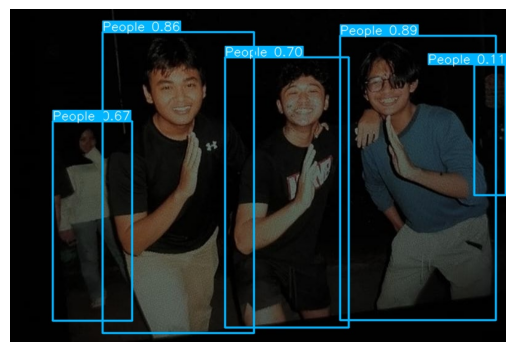

In [23]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("runs/detect/predict/wongedan.jpg")
plt.imshow(img)
plt.axis("off")

In [24]:
results = model.predict(
    source="sepedada.jpg",
    imgsz=640,
    conf=0.1,
    save=True
)



image 1/1 /content/sepedada.jpg: 448x640 1 Bicycle, 1 People, 13.0ms
Speed: 3.4ms preprocess, 13.0ms inference, 1.8ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


(np.float64(-0.5), np.float64(611.5), np.float64(407.5), np.float64(-0.5))

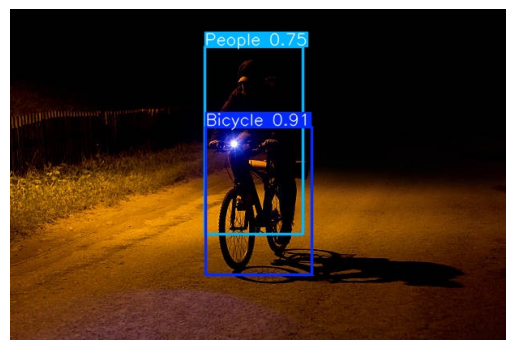

In [25]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("runs/detect/predict/sepedada.jpg")
plt.imshow(img)
plt.axis("off")

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 33.1 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/ngelatihsiyolo/train1/weights/best.pt')


In [5]:
results = model.predict(
    source="busbusan.jpg",
    imgsz=640,
    conf=0.1,
    save=True
)



image 1/1 /content/busbusan.jpg: 480x640 1 Bus, 9 Peoples, 43.6ms
Speed: 11.2ms preprocess, 43.6ms inference, 115.6ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


(np.float64(-0.5), np.float64(3263.5), np.float64(2447.5), np.float64(-0.5))

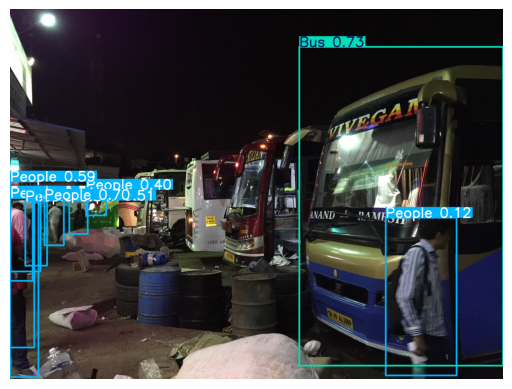

In [6]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("runs/detect/predict/busbusan.jpg")
plt.imshow(img)
plt.axis("off")